# Hourly Orders Forecasting: Baseline vs Gradient Boosting
Uses `sales_data.csv` (synthetic data from `generate_data.ipynb`). Keep both files in the same folder.

Steps:
1. Load data and look at it (charts)
2. Baseline: same hour last week
3. Gradient boosting model (scikit-learn HistGradientBoostingRegressor, LightGBM-style)
4. Compare with MAE / WAPE / MAPE

**Install once (terminal, inside your venv):** `pip install scikit-learn pandas numpy matplotlib`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

plt.rcParams["figure.figsize"] = (11, 4)

## 1. Load data and explore

In [2]:
df = pd.read_csv("sales_data.csv", parse_dates=["datetime"])
print(df.shape)
print("Date range:", df["datetime"].min(), "->", df["datetime"].max())
df.head()

(7727, 10)
Date range: 2026-07-01 12:00:00 -> 2026-10-17 23:00:00


,datetime,branch,hour,day_of_week,is_weekend,is_holiday,temperature,rain,orders,sales
0,2026-07-01 12:00:00,Bahria Town,12,2,0,0,36.5,1,7,12467
1,2026-07-01 12:00:00,DHA Phase 4,12,2,0,0,36.5,1,8,10819
2,2026-07-01 12:00:00,DHA Phase 6,12,2,0,0,36.5,1,1,1318
3,2026-07-01 12:00:00,Emporium Mall,12,2,0,0,36.5,1,7,8450
4,2026-07-01 12:00:00,Johar Town,12,2,0,0,36.5,1,6,9364


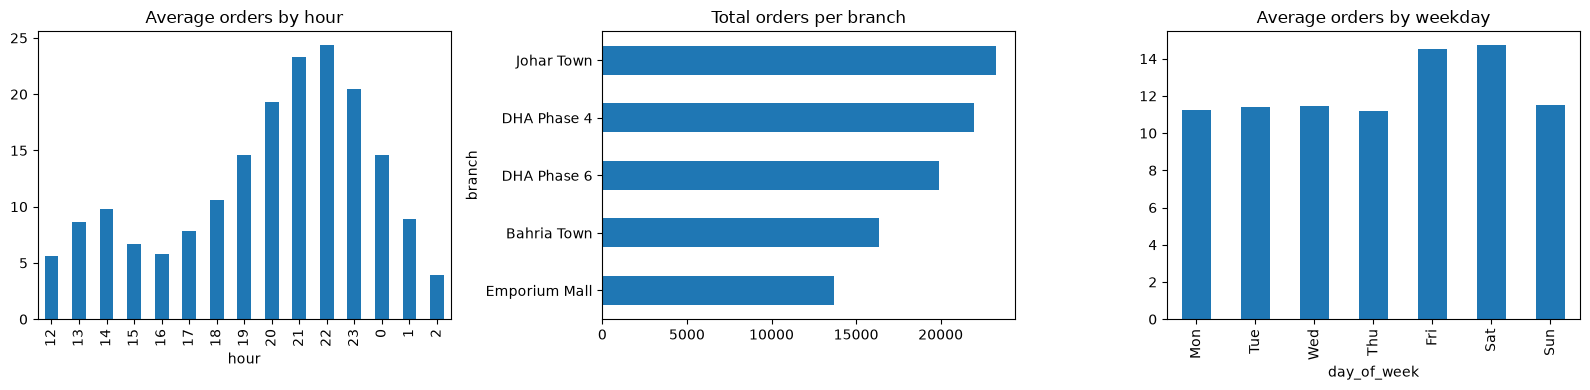

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

order = list(range(12, 24)) + [0, 1, 2]
df.groupby("hour")["orders"].mean().reindex(order).plot(kind="bar", ax=axes[0], title="Average orders by hour")

df.groupby("branch")["orders"].sum().sort_values().plot(kind="barh", ax=axes[1], title="Total orders per branch")

dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df.groupby("day_of_week")["orders"].mean().rename(index=dict(enumerate(dow_names))).plot(
    kind="bar", ax=axes[2], title="Average orders by weekday")

plt.tight_layout()
plt.show()

## 2. Build features
For every row we add what we would know in real life when forecasting:
- **lag_7d**: orders in the same hour, same branch, 7 days ago
- **lag_1d**: same hour yesterday
- **roll_mean_7d**: average of the same hour over the previous 7 days (shifted so it never sees the future)

Weather columns (`temperature`, `rain`) are assumed to come from a weather forecast.

In [4]:
df = df.sort_values(["branch", "datetime"]).reset_index(drop=True)

def add_lag(frame, days, name):
    lagged = frame[["branch", "datetime", "orders"]].copy()
    lagged["datetime"] = lagged["datetime"] + pd.Timedelta(days=days)
    lagged = lagged.rename(columns={"orders": name})
    return frame.merge(lagged, on=["branch", "datetime"], how="left")

df = add_lag(df, 7, "lag_7d")
df = add_lag(df, 1, "lag_1d")

# rolling mean of the same hour over the previous 7 days (excluding today)
df = df.sort_values(["branch", "hour", "datetime"]).reset_index(drop=True)
df["roll_mean_7d"] = (
    df.groupby(["branch", "hour"])["orders"]
      .transform(lambda s: s.shift(1).rolling(7, min_periods=3).mean())
)
df = df.sort_values(["datetime", "branch"]).reset_index(drop=True)

df["branch_code"] = df["branch"].astype("category").cat.codes

# first week has no lag_7d, so drop those rows
data = df.dropna(subset=["lag_7d", "lag_1d", "roll_mean_7d"]).reset_index(drop=True)
print("Rows after dropping the first week:", len(data))

Rows after dropping the first week: 7230


## 3. Train / test split (by time)
We never shuffle time series. The **last 14 days** are the test set; everything before is training.

In [5]:
TEST_DAYS = 14
cutoff = data["datetime"].max() - pd.Timedelta(days=TEST_DAYS)
train = data[data["datetime"] <= cutoff]
test = data[data["datetime"] > cutoff]
print(f"Train: {len(train):,} rows | Test: {len(test):,} rows")
print("Test period starts:", test["datetime"].min())

Train: 6,236 rows | Test: 994 rows
Test period starts: 2026-10-04 00:00:00


## 4. Baseline: same hour last week

In [6]:
def wape(y_true, y_pred):
    # Weighted absolute percentage error: sum|error| / sum(actual). Safe when actual has zeros.
    return np.abs(y_true - y_pred).sum() / np.abs(y_true).sum() * 100

def mape(y_true, y_pred):
    # Classic MAPE, computed only where actual orders > 0
    mask = y_true > 0
    return (np.abs(y_true[mask] - y_pred[mask]) / y_true[mask]).mean() * 100

y_test = test["orders"].values
baseline_pred = test["lag_7d"].values

print("Baseline (same hour last week)")
print(f"  MAE  : {mean_absolute_error(y_test, baseline_pred):.2f} orders")
print(f"  WAPE : {wape(y_test, baseline_pred):.1f}%")
print(f"  MAPE : {mape(y_test, baseline_pred):.1f}%")

Baseline (same hour last week)
  MAE  : 3.90 orders
  WAPE : 33.1%
  MAPE : 45.7%


## 5. Gradient boosting model

In [7]:
FEATURES = ["hour", "day_of_week", "is_weekend", "is_holiday", "temperature", "rain",
            "branch_code", "lag_7d", "lag_1d", "roll_mean_7d"]

model = HistGradientBoostingRegressor(
    max_iter=400,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42,
)
model.fit(train[FEATURES], train["orders"])

lgbm_pred = np.clip(model.predict(test[FEATURES]), 0, None)

print("Gradient Boosting")
print(f"  MAE  : {mean_absolute_error(y_test, lgbm_pred):.2f} orders")
print(f"  WAPE : {wape(y_test, lgbm_pred):.1f}%")
print(f"  MAPE : {mape(y_test, lgbm_pred):.1f}%")

Gradient Boosting
  MAE  : 2.79 orders
  WAPE : 23.7%
  MAPE : 34.3%


## 6. Comparison

In [8]:
results = pd.DataFrame({
    "Model": ["Baseline (last week)", "Gradient Boosting"],
    "MAE": [mean_absolute_error(y_test, baseline_pred), mean_absolute_error(y_test, lgbm_pred)],
    "WAPE %": [wape(y_test, baseline_pred), wape(y_test, lgbm_pred)],
    "MAPE %": [mape(y_test, baseline_pred), mape(y_test, lgbm_pred)],
}).round(2)
display(results)

improvement = (results.loc[0, "MAE"] - results.loc[1, "MAE"]) / results.loc[0, "MAE"] * 100
print(f"Gradient boosting MAE is {improvement:.1f}% lower than the baseline.")

,Model,MAE,WAPE %,MAPE %
0,Baseline (last week),3.90,33.09,45.72
1,Gradient Boosting,2.79,23.69,34.27


Gradient boosting MAE is 28.5% lower than the baseline.


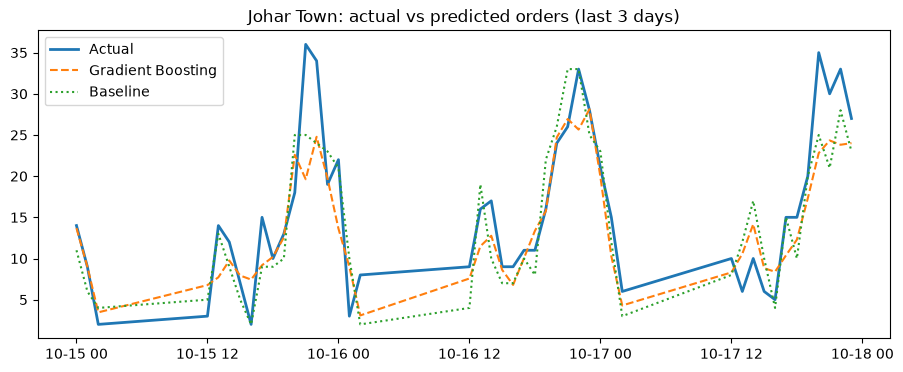

In [9]:
# Actual vs predicted for one branch, last 3 days of the test period
branch_name = "Johar Town"
view = test[test["branch"] == branch_name].copy()
view["lgbm"] = lgbm_pred[(test["branch"] == branch_name).values]
view["baseline"] = baseline_pred[(test["branch"] == branch_name).values]
view = view[view["datetime"] > view["datetime"].max() - pd.Timedelta(days=3)]

plt.plot(view["datetime"], view["orders"], label="Actual", linewidth=2)
plt.plot(view["datetime"], view["lgbm"], label="Gradient Boosting", linestyle="--")
plt.plot(view["datetime"], view["baseline"], label="Baseline", linestyle=":")
plt.title(f"{branch_name}: actual vs predicted orders (last 3 days)")
plt.legend()
plt.show()

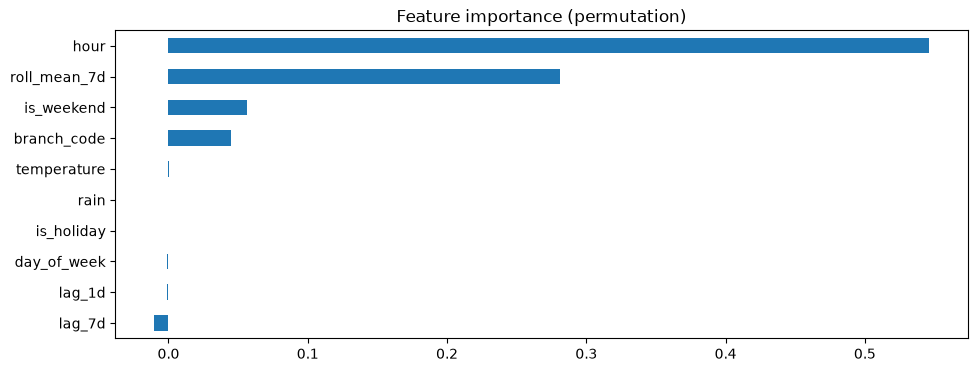

In [10]:
# Which features matter most? (how much the error grows if a feature is shuffled)
result = permutation_importance(model, test[FEATURES], test["orders"],
                                n_repeats=5, random_state=42)
pd.Series(result.importances_mean, index=FEATURES).sort_values().plot(
    kind="barh", title="Feature importance (permutation)")
plt.show()

## 7. Reading the results
- The data is **synthetic with random (Poisson) noise**, so some error can never be removed, even by a perfect model.
- If the model beats the baseline, say so with the numbers: "MAE dropped from X to Y orders per hour."
- With real POS data you would retrain, re-check these numbers, and test on more than 14 days.


---